<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformer sentiment analysis on IMDb movie reviews

Train a small **encoder-only transformer from scratch** to classify movie reviews as negative (0) or positive (1). Unlike a language model, this model reads the whole review and predicts one label.

We will download IMDb, build a word vocabulary from the training split, explore self-attention, train a classifier, and evaluate it on held-out reviews. This is a teaching model, not a pretrained BERT: it starts with random weights and may need more training or tuning for strong accuracy.

**Setup:** Run cells in order. Install dependencies in the notebook environment if needed: `%pip install torch datasets matplotlib`. The first dataset download needs internet access and disk space. Training can be slow on CPU; reduce `TRAIN_LIMIT` for a quick experiment. The test set is used only for the final evaluation.

In [ ]:
import copy
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import load_dataset

print("PyTorch:", torch.__version__)

/Users/mironshoh/Documents/dl/dl/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.10.0


In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Device:", DEVICE)

torch.manual_seed(42)

Device: mps


In [ ]:
# Keep sequences short: attention work and memory grow roughly as T².
MAX_LEN = 128
VOCAB_LIMIT = 20_000       # includes special tokens
BATCH_SIZE = 32
EMBED_SIZE = 128
NUM_HEADS = 4              # EMBED_SIZE must be divisible by NUM_HEADS
NUM_LAYERS = 2
FF_SIZE = 256
DROPOUT = 0.1
LEARNING_RATE = 3e-4
EPOCHS = 5
TRAIN_LIMIT = None         # e.g. 2000 for a quick smoke test; None uses all
assert EMBED_SIZE % NUM_HEADS == 0

## 1. Load and split the reviews

IMDb has 25,000 labeled training reviews and 25,000 labeled test reviews. We shuffle the original training set with a fixed seed and reserve 10% for validation. Build the vocabulary **only from the resulting training reviews**, so validation and test text cannot influence it. `TRAIN_LIMIT` applies after the split.

In [ ]:
imdb = load_dataset("imdb")
splits = imdb["train"].train_test_split(test_size=0.1, seed=42, stratify_by_column="label")
train_reviews = splits["train"]
val_reviews = splits["test"]
test_reviews = imdb["test"]
if TRAIN_LIMIT is not None:
    assert 0 < TRAIN_LIMIT <= len(train_reviews)
    train_reviews = train_reviews.select(range(TRAIN_LIMIT))
print("Train / validation / test:", len(train_reviews), len(val_reviews), len(test_reviews))
print("Label:", train_reviews[0]["label"])
print(train_reviews[0]["text"][:500])

Train / validation / test: 22500 2500 25000
Label: 0
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link the prophecies as well as it can to what was happening in the times it was made, making it obviously dated and kind of silly.<br /><br />The reenactments look like they are out of "Unsolved Mysteries" b


## 2. Tokenize and build a vocabulary

We lowercase words and punctuation with a simple regex, replacing IMDb's HTML line breaks with spaces. This is intentionally simpler than a production subword tokenizer. Unknown words become `<unk>`; `<pad>` fills unused positions. Long reviews are truncated, so the model cannot see their endings.

In [ ]:
PAD, UNK = "<pad>", "<unk>"
def tokenize(text):
    text = re.sub(r"<br\s*/?>", " ", text.lower())
    return re.findall(r"\w+|[^\w\s]", text)

counts = Counter(token for review in train_reviews["text"] for token in tokenize(review))
itos = [PAD, UNK] + [word for word, _ in counts.most_common(VOCAB_LIMIT - 2)]
stoi = {word: i for i, word in enumerate(itos)}
PAD_ID, UNK_ID = stoi[PAD], stoi[UNK]
print("Vocabulary size:", len(itos))
print("Example tokens:", tokenize(train_reviews[0]["text"])[:20])

Vocabulary size: 20000
Example tokens: ['every', 'generation', 'fully', 'believes', 'it', 'is', 'living', 'in', 'the', 'end', 'times', '.', 'this', 'has', 'been', 'true', 'for', 'thousands', 'of', 'years']


In [ ]:
def encode(text):
    ids = [stoi.get(token, UNK_ID) for token in tokenize(text)[:MAX_LEN]]
    # An empty review must still have one unmasked token for attention and pooling.
    return ids or [UNK_ID]

def collate_batch(examples):
    encoded = [encode(example["text"]) for example in examples]
    length = max(map(len, encoded))  # pad only to the longest review in this batch
    x = torch.full((len(encoded), length), PAD_ID, dtype=torch.long)
    for i, ids in enumerate(encoded):
        x[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    y = torch.tensor([example["label"] for example in examples], dtype=torch.long)
    return x, y

train_loader = DataLoader(train_reviews, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(val_reviews, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_reviews, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
x_batch, y_batch = next(iter(train_loader))
print("Token ids:", x_batch.shape, "Labels:", y_batch.shape)
print("First review:", [itos[i] for i in x_batch[0, :20].tolist()])

Token ids: torch.Size([32, 128]) Labels: torch.Size([32])
First review: ['this', 'is', 'a', 'story', 'of', 'a', 'jewish', 'dysfunctional', 'family', '.', 'the', 'parents', 'have', 'divorced', 'and', 'mom', 'remains', 'back', 'east', 'in']


## 3. How self-attention works

For each token, learned projections produce a **query** Q, **key** K, and **value** V. A query scores every key, softmax converts the scores into weights, and the weighted values form a context-aware representation:

$$\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + M\right)V$$

Here `M` masks padding keys with negative infinity, so real tokens cannot attend to padding. Each attention head learns different projections; multi-head attention concatenates their results and projects them back to the embedding size. Unlike the LSTM's sequential state updates, tokens can exchange information across the review in one layer. This is **bidirectional** attention: no causal mask is needed for classification.

The toy example below calculates one head directly. Its weights are illustrative, not learned.

In [ ]:
torch.manual_seed(42)
q = torch.randn(1, 3, 4)  # batch=1, 3 tokens, head dimension=4
k = torch.randn(1, 3, 4)
v = torch.randn(1, 3, 4)
padding = torch.tensor([[False, False, True]])  # third key is padding
scores = q @ k.transpose(-2, -1) / math.sqrt(k.size(-1))
scores = scores.masked_fill(padding[:, None, :], float("-inf"))
weights = scores.softmax(dim=-1)
context = weights @ v
print("Attention weights (query × key):\n", weights[0])
print("Context shape:", context.shape)

Attention weights (query × key):
 tensor([[0.4934, 0.5066, 0.0000],
        [0.3920, 0.6080, 0.0000],
        [0.5616, 0.4384, 0.0000]])
Context shape: torch.Size([1, 3, 4])


## 4. Build the transformer classifier

Token embeddings alone contain no ordering information, so we add a learned **position embedding**. Each encoder layer uses multi-head self-attention, a position-wise feed-forward network, residual connections, layer normalization, and dropout. PyTorch's `TransformerEncoderLayer` implements these pieces; `batch_first=True` keeps shapes in `(batch, time, features)` order.

The padding mask prevents attention to padding **keys**, but padded query positions can still produce outputs. We therefore exclude them again when mean-pooling. The linear head maps the pooled review vector to two raw logits. Cross-entropy applies the softmax internally.

In [ ]:
class SentimentTransformer(nn.Module):
    def __init__(self, vocab_size, max_len, embed_size, num_heads, num_layers, ff_size, dropout):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, embed_size, padding_idx=PAD_ID)
        self.position_embedding = nn.Embedding(max_len, embed_size)
        self.dropout = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_size, nhead=num_heads, dim_feedforward=ff_size,
            dropout=dropout, batch_first=True,
        )
        # Disable the optional nested-tensor fast path for consistent device behavior.
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers, enable_nested_tensor=False)
        # TransformerEncoder copies the same initial layer; give each copy its own initialization.
        for block in self.encoder.layers:
            for parameter in block.parameters():
                if parameter.dim() > 1:
                    nn.init.xavier_uniform_(parameter)
        self.classifier = nn.Linear(embed_size, 2)

    def forward(self, tokens):
        padding_mask = tokens.eq(PAD_ID)               # (B, T), True means ignore
        positions = torch.arange(tokens.size(1), device=tokens.device).unsqueeze(0)
        x = self.token_embedding(tokens) + self.position_embedding(positions)  # (B, T, E)
        x = self.encoder(self.dropout(x), src_key_padding_mask=padding_mask)
        valid = (~padding_mask).unsqueeze(-1)           # (B, T, 1)
        pooled = (x * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1)
        return self.classifier(pooled)                  # (B, 2) logits

model = SentimentTransformer(
    len(itos), MAX_LEN, EMBED_SIZE, NUM_HEADS, NUM_LAYERS, FF_SIZE, DROPOUT
).to(DEVICE)
print(model)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Logits shape:", model(x_batch.to(DEVICE)).shape)

SentimentTransformer(
  (token_embedding): Embedding(20000, 128, padding_idx=0)
  (position_embedding): Embedding(128, 128)
  (dropout): Dropout(p=0.1, inplace=False)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)
Parameters: 2,841,602
Logits shape: torch.Size([32, 2])


## 5. Train and validate

AdamW updates the parameters from cross-entropy loss. We report example-weighted loss and accuracy, and retain the weights with the lowest validation loss. Training a transformer from scratch on a small dataset is an experiment: accuracy depends on the seed, compute, sequence length, and hyperparameters.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

def run_epoch(loader, training):
    model.train(training)
    total_loss = total_correct = total_examples = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total_examples += y.size(0)
    return total_loss / total_examples, total_correct / total_examples

In [ ]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_loss = float("inf")
best_state = None
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
        history[key].append(value)
    if val_loss < best_loss:
        best_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.3f} | "
          f"val loss {val_loss:.4f}, acc {val_acc:.3f}")
model.load_state_dict(best_state)
print("Restored weights with lowest validation loss:", round(best_loss, 4))

Epoch 01/5 | train loss 0.6005, acc 0.665 | val loss 0.5180, acc 0.736
Epoch 02/5 | train loss 0.4891, acc 0.759 | val loss 0.4814, acc 0.760
Epoch 03/5 | train loss 0.4267, acc 0.802 | val loss 0.4458, acc 0.788
Epoch 04/5 | train loss 0.3828, acc 0.829 | val loss 0.4385, acc 0.802
Epoch 05/5 | train loss 0.3506, acc 0.847 | val loss 0.4543, acc 0.802
Restored weights with lowest validation loss: 0.4385


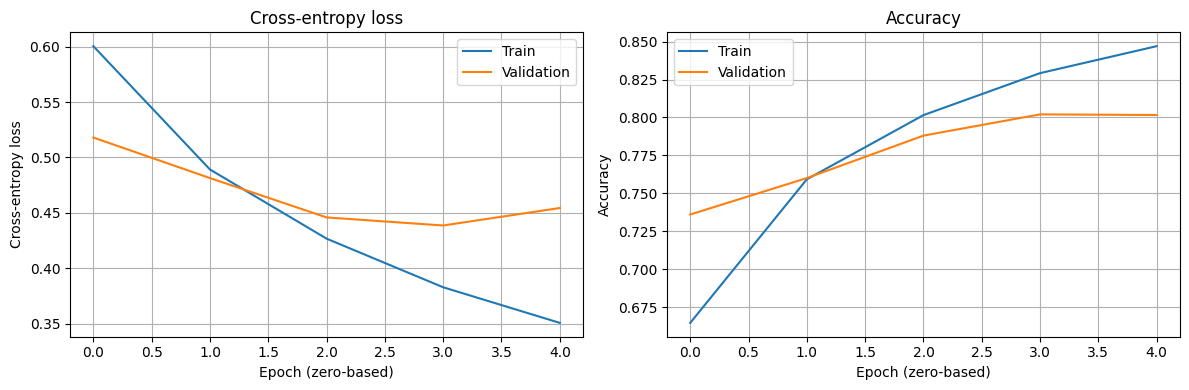

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ("loss", "acc"), ("Cross-entropy loss", "Accuracy")):
    ax.plot(history["train_" + metric], label="Train")
    ax.plot(history["val_" + metric], label="Validation")
    ax.set(xlabel="Epoch (zero-based)", ylabel=title, title=title)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 6. Evaluate and try your own reviews

Evaluate the selected model once on the untouched test split. The output probability is the model's softmax score, not a guarantee of calibrated confidence. Recall that only the first `MAX_LEN` tokens are considered.

In [ ]:
test_loss, test_acc = run_epoch(test_loader, training=False)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.3f}")

Test loss: 0.4530 | Test accuracy: 0.793


In [ ]:
@torch.no_grad()
def predict_sentiment(text):
    model.eval()
    x = torch.tensor([encode(text)], dtype=torch.long, device=DEVICE)
    probabilities = model(x).softmax(dim=-1)[0].cpu()
    return {"negative": probabilities[0].item(), "positive": probabilities[1].item()}

for review in ["A charming, funny movie with wonderful performances.",
               "A boring mess. I couldn't wait for it to end."]:
    print(review, predict_sentiment(review))

A charming, funny movie with wonderful performances. {'negative': 0.002642459701746702, 'positive': 0.9973575472831726}
A boring mess. I couldn't wait for it to end. {'negative': 0.9883053302764893, 'positive': 0.01169466320425272}


## Experiments

- Change `MAX_LEN`: what happens to training time and accuracy when the model can read more of each review?
- Try one versus two encoder layers, or change the number of attention heads while keeping the embedding size divisible by it.
- Compare train and validation curves for overfitting. Adjust dropout or training epochs using validation results, then reserve the test set for a final evaluation.
- The simple tokenizer loses information about rare words. How might a subword tokenizer or pretrained transformer help?